In [2]:
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt

logits = torch.tensor([[2.0,1.0,0.1]])

probabilities = torch.softmax(logits, dim=1)

print("Logits:",logits)
print("Probabilities:", probabilities)
print("Sum:", probabilities.sum().item())
print("Predicted Class:", probabilities.argmax(dim=1))

Logits: tensor([[2.0000, 1.0000, 0.1000]])
Probabilities: tensor([[0.6590, 0.2424, 0.0986]])
Sum: 1.0000001192092896
Predicted Class: tensor([0])


In [3]:
correct_class = torch.tensor([1])

loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(logits, correct_class)

print("Cross-Entropy Loss: ", loss.item())
print("Manual Loss: ", -torch.log(probabilities[0,1]).item())

Cross-Entropy Loss:  1.4170299768447876
Manual Loss:  1.4170299768447876


In [4]:
torch.manual_seed(42)

centers = torch.tensor([
    [-2.0, -2.0],
    [2.0, -2.0],
    [0.0, 2.0]
])

X = torch.cat([
    torch.randn(100, 2) * 0.6 + center
    for center in centers
])

y = torch.arange(3).repeat_interleave(100)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First point:", X[0])
print("First label:", y[0])

X shape: torch.Size([300, 2])
y shape: torch.Size([300])
First point: tensor([-0.8439, -1.1076])
First label: tensor(0)


In [5]:
indices = torch.randperm(len(X))

train_idx = indices[:210]
val_idx = indices[210:255]
test_idx = indices[255:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([210, 2]) torch.Size([45, 2]) torch.Size([45, 2])


In [6]:
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 99


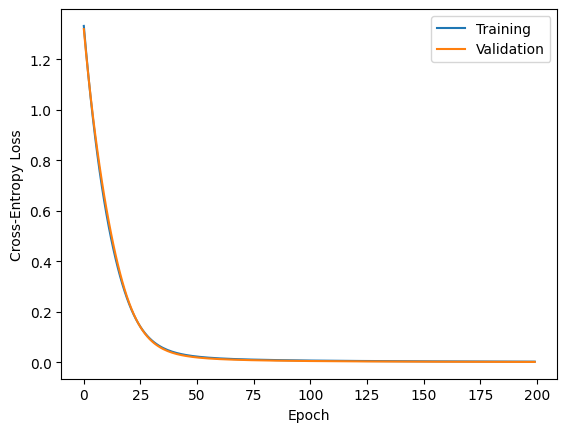

In [7]:
train_losses = []
val_losses = []

for epoch in range(200):
    model.train()

    logits = model(X_train)
    train_loss = loss_fn(logits, y_train)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val)
        val_loss = loss_fn(val_logits, y_val)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.show()

In [8]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test)
    test_predictions = test_logits.argmax(dim=1)

    test_accuracy = (test_predictions == y_test).float().mean()

print("Test accuracy:", test_accuracy.item())
print("First 10 predictions:", test_predictions[:10])
print("First 10 actual labels:", y_test[:10])

Test accuracy: 1.0
First 10 predictions: tensor([0, 1, 1, 0, 0, 2, 1, 1, 1, 0])
First 10 actual labels: tensor([0, 1, 1, 0, 0, 2, 1, 1, 1, 0])


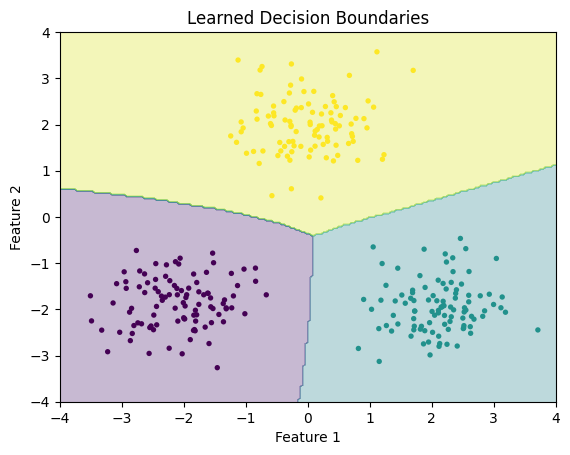

In [9]:
import numpy as np

xx, yy = np.meshgrid(
    np.linspace(-4, 4, 200),
    np.linspace(-4, 4, 200)
)

grid = torch.tensor(
    np.c_[xx.ravel(), yy.ravel()],
    dtype=torch.float32
)

model.eval()
with torch.no_grad():
    regions = model(grid).argmax(dim=1).reshape(xx.shape)

plt.contourf(xx, yy, regions.numpy(), alpha=0.3)

plt.scatter(X[:, 0], X[:, 1], c=y, s=15, edgecolors="none")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Learned Decision Boundaries")
plt.show()

In [10]:
model.eval()

sample = torch.tensor([
    [-2.0, -2.0],
    [2.0, -2.0],
    [0.0, 2.0]
])

with torch.no_grad():
    scores = model(sample)
    probabilities = torch.softmax(scores, dim=1)
    predictions = scores.argmax(dim=1)

print("Raw logits:\n", scores)
print("Probabilities:\n", probabilities)
print("Predicted classes:", predictions)

Raw logits:
 tensor([[ 2.9996, -4.7962, -5.7273],
        [-4.4953,  4.1091, -4.5262],
        [-5.4808, -4.5676,  5.1370]])
Probabilities:
 tensor([[9.9943e-01, 4.1120e-04, 1.6206e-04],
        [1.8324e-04, 9.9964e-01, 1.7766e-04],
        [2.4473e-05, 6.0996e-05, 9.9991e-01]])
Predicted classes: tensor([0, 1, 2])


In [11]:
a, b = np.meshgrid(
    [-2, 0, 2],
    [-2, 0, 2]
)

print(a)
print(b)

[[-2  0  2]
 [-2  0  2]
 [-2  0  2]]
[[-2 -2 -2]
 [ 0  0  0]
 [ 2  2  2]]
